<a href="https://colab.research.google.com/github/RoihansLab/Data-Mining-Project/blob/main/youtube_comment_sentiment/Classification/classification_modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Klasifikasi Sentimen & Sikap Publik terhadap AI yang Menggantikan Pekerjaan Manusia Berdasarkan Komentar YouTube**

**Mata Kuliah:** Data Mining

**Nama Anggota Kelompok:**

1.   Muhammad Rafa Enrico (Ketua - 4.33.24.2.15)
2.   Roihan Saputra (4.33.24.2.20)

**Kelas TI-3C**

**Program Studi:** D4 Teknologi Rekayasa Komputer, Politeknik Negeri Semarang

---
## Gambaran Umum Notebook
Notebook ini berfokus pada tahapan **Machine Learning & Klasifikasi** menggunakan dataset komentar YouTube berlabel yang telah disiapkan pada tahap *Data Preparation*:
1. **Text Preprocessing:** Case folding, removing punctuation/angka, filtering (stopwords Indonesia & Inggris), tokenizing, dan stemming (Sastrawi & Porter Stemmer).
2. **Ekstraksi Fitur:** TF-IDF n-gram, Word Embedding (FastText), dan Pre-trained Sentence Embedding (e5).
3. **Pemodelan Klasifikasi:** Melatih & mengevaluasi algoritma klasik (Decision Tree, Naïve Bayes, Random Forest, Logistic Regression, Extra Trees, KNN, Linear SVM) serta model Transformer.
4. **Optimasi & Evaluasi:** Hyperparameter tuning dengan Bayesian Search (Optuna), analisis Confusion Matrix, dan perbandingan performa model.


# **1. Import Library & Setup Environment**

Seluruh library pendukung untuk preprocessing teks, ekstraksi fitur, pemodelan machine learning, dan evaluasi disiapkan di sel ini. Nilai `SEED = 42` mengunci semua sumber acak agar eksperimen dapat direproduksi secara konsisten.


In [1]:
# Pasang library NLP, modeling, dan optimasi jika belum terinstal
%pip install Sastrawi nltk gensim sentence-transformers optuna scikit-learn matplotlib seaborn joblib transformers torch --quiet

import os
import re
import random
import string
import unicodedata
from collections import Counter
from tqdm import tqdm

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Preprocessing Teks NLP
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Ekstraksi Fitur & Split Data
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import make_pipeline
from gensim.models import FastText
from sentence_transformers import SentenceTransformer

# Model Klasifikasi & Metrik
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score, ConfusionMatrixDisplay

# Deep Learning & Optimasi
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
import optuna

# Kunci random seed untuk reprodusibilitas
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("✅ Setup library berhasil.")
print("Perangkat komputasi:", "GPU: " + torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


c:\Users\ACER\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1025 15:35:00.904000 35828 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


✅ Setup library berhasil.
Perangkat komputasi: CPU


# **6. Text Preprocessing**

Bab 3 hanya membersihkan data mentah. Bab ini mengolah **teks komentar** supaya siap dibaca model klasik: 6.2 case folding → 6.3 removing → 6.4 filtering (stopword) → 6.5 tokenizing → 6.6 stemming.

Hasil olahan disimpan di kolom baru `teks` (dan `token`), sedangkan kolom `comment` tetap asli karena dipakai oleh model deep learning dan embedding e5 di Bab 8.

## **6.1 Memuat Data Berlabel**

Mengenali data berlabel hasil Bab 5: berapa barisnya, kolom apa saja, dan bagaimana sebaran labelnya.

**Sel ini:** memuat data berlabel `youtube_comments_label_claude_v3.csv` ke tabel `df`. Lokasi berkas dicari otomatis, jadi sel yang sama bisa dijalankan di Google Colab maupun laptop.

In [2]:
# Lokasi data: Google Colab atau laptop
for path in ["/content/youtube_comments_label_claude_v3.csv", "../../datasets/youtube_comments_label_claude_v3.csv", "datasets/youtube_comments_label_claude_v3.csv"]:
    if os.path.exists(path):
        break

df = pd.read_csv(path)
print("Data dimuat dari:", path)
df.head()

Data dimuat dari: ../../datasets/youtube_comments_label_claude_v3.csv


,video_title,comment,likes,author_id,bahasa,label
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,0,Indonesia,tidak relevan
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,189,1,Indonesia,negatif
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,6,2,Indonesia,negatif
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,588,3,Indonesia,negatif
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi meningk...,85,4,Indonesia,netral


**Sel ini:** menampilkan jumlah baris, kolom, dan tipe data.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3935 entries, 0 to 3934
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   video_title  3935 non-null   object
 1   comment      3935 non-null   object
 2   likes        3935 non-null   int64 
 3   author_id    3935 non-null   int64 
 4   bahasa       3935 non-null   object
 5   label        3935 non-null   object
dtypes: int64(2), object(4)
memory usage: 184.6+ KB


**Sel ini:** menghitung jumlah komentar untuk setiap label.

In [4]:
df["label"].value_counts()

label
tidak relevan    1427
negatif          1199
positif           689
netral            620
Name: count, dtype: int64

**Hasil:**

- Ada **3.929 komentar** dan 6 kolom, **tidak ada nilai kosong**.
- Kolom yang dipakai untuk klasifikasi hanya dua: `comment` (teks) dan `label` (jawaban).
- Sebaran label: tidak relevan 1.430, negatif 1.203, positif 680, netral 616. Netral paling sedikit (15,7%), jadi perlu diperhatikan saat klasifikasi.
- Bahasa: Inggris 2.492 komentar, Indonesia 1.437 komentar.

## **6.2 Case Folding**

Semua huruf diubah menjadi huruf kecil, supaya "AI", "Ai", dan "ai" dianggap kata yang sama. Hasilnya disimpan di kolom baru `teks`, sedangkan `comment` tetap asli.

**Sel ini:** menghitung komentar yang masih punya huruf besar.

In [5]:
# Cek: berapa komentar yang masih punya huruf besar
(df["comment"] != df["comment"].str.lower()).sum()

np.int64(3414)

**Sel ini:** mengubah semua huruf menjadi huruf kecil dan menyimpannya di kolom `teks`.

In [6]:
df["teks"] = df["comment"].str.lower()
df[["comment", "teks"]].head()

,comment,teks
0,Bahas imigrant maroko yg nyebrang ke spanyol d...,bahas imigrant maroko yg nyebrang ke spanyol d...
1,Menurut saya jika semua pengusaha berpikiran s...,menurut saya jika semua pengusaha berpikiran s...
2,jujur ya sebagai seorang yang bekerja di bidan...,jujur ya sebagai seorang yang bekerja di bidan...
3,Gw sebagai illustrator susah bener dapet klien...,gw sebagai illustrator susah bener dapet klien...
4,Niat untung -> efesiensi phk->produksi meningk...,niat untung -> efesiensi phk->produksi meningk...


**Hasil:** 3.405 dari 3.929 komentar punya huruf besar, dan sekarang semuanya sudah menjadi huruf kecil di kolom `teks`.

## **6.3 Removing**

Membuang bagian teks yang tidak dipakai model: URL, angka, tanda baca, karakter khusus (emoji dan simbol), dan spasi berlebih. Setiap jenis **dicek dulu**, lalu **hanya dibersihkan kalau ada**.

**Sel ini:** menyiapkan pola untuk setiap jenis yang akan dibuang, lalu menghitung berapa komentar yang mengandungnya.

In [7]:
pola = {
    "URL": r"https?://\S+|www\.\S+",
    "angka": r"\d",
    "tanda baca": "[" + re.escape(string.punctuation) + "]",
    "karakter khusus (emoji, simbol)": r"[^a-z0-9\s" + re.escape(string.punctuation) + "]",
    "spasi berlebih": r"\s{2,}|^\s|\s$",
}

# Cek: berapa komentar yang mengandung setiap jenis
cek_removing = lambda: pd.Series({nama: df["teks"].str.contains(p).sum() for nama, p in pola.items()})
cek_removing()

URL                                   0
angka                               693
tanda baca                         3293
karakter khusus (emoji, simbol)     677
spasi berlebih                        0
dtype: int64

**Sel ini:** membersihkan jenis yang ditemukan (diganti spasi supaya kata tidak menempel), lalu merapikan spasi.

In [8]:
# Bersihkan hanya jenis yang ada (diganti spasi supaya kata tidak menempel)
for nama, p in pola.items():
    if nama != "spasi berlebih" and df["teks"].str.contains(p).sum() > 0:
        df["teks"] = df["teks"].str.replace(p, " ", regex=True)
        print("dibersihkan:", nama)

# Terakhir, rapikan spasi berlebih yang muncul setelah pembersihan
df["teks"] = df["teks"].str.split().str.join(" ")

dibersihkan: angka
dibersihkan: tanda baca
dibersihkan: karakter khusus (emoji, simbol)


**Sel ini:** mengecek ulang. Semua jenis harus bernilai `0`.

In [9]:
# Cek ulang: semua harus 0
cek_removing()

URL                                0
angka                              0
tanda baca                         0
karakter khusus (emoji, simbol)    0
spasi berlebih                     0
dtype: int64

**Sel ini:** menampilkan contoh teks sebelum dan sesudah dibersihkan.

In [10]:
df[["comment", "teks"]].head()

,comment,teks
0,Bahas imigrant maroko yg nyebrang ke spanyol d...,bahas imigrant maroko yg nyebrang ke spanyol d...
1,Menurut saya jika semua pengusaha berpikiran s...,menurut saya jika semua pengusaha berpikiran s...
2,jujur ya sebagai seorang yang bekerja di bidan...,jujur ya sebagai seorang yang bekerja di bidan...
3,Gw sebagai illustrator susah bener dapet klien...,gw sebagai illustrator susah bener dapet klien...
4,Niat untung -> efesiensi phk->produksi meningk...,niat untung efesiensi phk produksi meningkat t...


**Hasil:**

| Jenis | Sebelum | Sesudah |
|---|---|---|
| URL | 0 (sudah dibersihkan di Bab 3) | 0 |
| angka | 694 | 0 |
| tanda baca | 3.285 | 0 |
| karakter khusus (emoji, simbol) | 677 | 0 |
| spasi berlebih | 0 (sudah dirapikan di Bab 3) | 0 |

Tidak ada komentar yang menjadi kosong setelah dibersihkan.

## **6.4 Filtering (Stopword Removal)**

Membuang kata umum yang tidak membawa makna, misalnya "yang", "dan", "the", "is". Daftarnya gabungan stopword bahasa Indonesia (Sastrawi) dan bahasa Inggris (scikit-learn).

**Kata negasi tetap disimpan**, karena membalik makna kalimat: "AI **tidak** akan menggantikan pekerjaan" berbeda jauh dengan "AI akan menggantikan pekerjaan".

**Sel ini:** menyusun daftar stopword (tanpa kata negasi), lalu menghitung komentar yang mengandung stopword.

In [11]:
stopword = set(StopWordRemoverFactory().get_stop_words()) | set(ENGLISH_STOP_WORDS)
negasi = {"tidak", "belum", "nggak", "not", "no", "nor", "never", "nothing", "none", "cannot"}
stopword = stopword - negasi
print("Jumlah stopword:", len(stopword))

# Cek: berapa komentar yang mengandung stopword
df["teks"].apply(lambda t: any(kata in stopword for kata in t.split())).sum()

Jumlah stopword: 431


np.int64(3719)

**Sel ini:** membuang stopword dari setiap komentar dan membandingkan rata-rata jumlah kata sebelum dan sesudahnya.

In [12]:
sebelum = df["teks"].str.split().str.len().mean()
df["teks"] = df["teks"].apply(lambda t: " ".join(kata for kata in t.split() if kata not in stopword))
print(f"Rata-rata jumlah kata per komentar: {sebelum:.1f} -> {df['teks'].str.split().str.len().mean():.1f}")

Rata-rata jumlah kata per komentar: 30.9 -> 18.0


**Sel ini:** membuang komentar yang menjadi kosong karena isinya stopword semua.

In [13]:
# Komentar yang isinya stopword semua menjadi kosong, jadi dibuang
print("Komentar kosong:", (df["teks"] == "").sum())
df = df[df["teks"] != ""].reset_index(drop=True)
print("Sisa data:", len(df))

Komentar kosong: 8
Sisa data: 3927


**Hasil:**

- 3.714 komentar mengandung stopword, dan 431 stopword dibuang dari teks.
- Rata-rata komentar menyusut dari 30,9 kata menjadi 18,0 kata (sekitar 42% kata terbuang).
- 8 komentar menjadi kosong karena isinya stopword semua (misalnya "Indeed, it was" dan "always have been"), jadi dibuang. **Sisa data: 3.921 komentar.**

## **6.5 Tokenizing**

Memecah setiap komentar menjadi daftar kata (token). Contoh: `"ai tidak butuh makan"` → `["ai", "tidak", "butuh", "makan"]`. Hasilnya disimpan di kolom `token`.

**Sel ini:** memecah teks menjadi token, lalu menghitung jumlah token dan kata unik.

In [14]:
df["token"] = df["teks"].str.split()

semua_token = [kata for daftar in df["token"] for kata in daftar]
print("Jumlah token:", len(semua_token))
print("Jumlah kata unik:", len(set(semua_token)))
df[["teks", "token"]].head()

Jumlah token: 70745
Jumlah kata unik: 13629


,teks,token
0,bahas imigrant maroko yg nyebrang spanyol donk...,"[bahas, imigrant, maroko, yg, nyebrang, spanyo..."
1,semua pengusaha berpikiran sama mengganti manu...,"[semua, pengusaha, berpikiran, sama, mengganti..."
2,jujur seorang bekerja bidang desain seni ilust...,"[jujur, seorang, bekerja, bidang, desain, seni..."
3,gw illustrator susah bener dapet klien baru or...,"[gw, illustrator, susah, bener, dapet, klien, ..."
4,niat untung efesiensi phk produksi meningkat t...,"[niat, untung, efesiensi, phk, produksi, menin..."


**Hasil:** 3.921 komentar dipecah menjadi **70.647 token** dengan **13.627 kata unik**. Kata unik inilah yang nanti menjadi kolom-kolom fitur di TF-IDF.

## **6.6 Stemming**

Mengubah setiap kata ke bentuk dasarnya, supaya kata yang maknanya sama dihitung sebagai satu kata. Contoh: "pengusaha" → "usaha", "mengganti" → "ganti", "approaching" → "approach".

Stemmer dipilih sesuai bahasa komentar: **Sastrawi** untuk bahasa Indonesia dan **Porter** untuk bahasa Inggris. Proses ini memakan waktu sekitar 2-3 menit.

**Sel ini:** menjalankan stemming sesuai bahasa komentar, lalu menyusun ulang kolom `teks` dari token hasil stemming.

In [15]:
stem_id = StemmerFactory().create_stemmer()   # bahasa Indonesia
stem_en = PorterStemmer()                      # bahasa Inggris
unik_sebelum = len({kata for daftar in df["token"] for kata in daftar})

df["token"] = [
    [stem_id.stem(kata) if bahasa == "Indonesia" else stem_en.stem(kata) for kata in token]
    for token, bahasa in zip(df["token"], df["bahasa"])
]
df["teks"] = df["token"].str.join(" ")         # teks akhir untuk TF-IDF

print("Kata unik:", unik_sebelum, "->", len({kata for daftar in df["token"] for kata in daftar}))
df[["comment", "teks"]].head()

Kata unik: 13629 -> 9848


,comment,teks
0,Bahas imigrant maroko yg nyebrang ke spanyol d...,bahas imigrant maroko yg nyebrang spanyol donk...
1,Menurut saya jika semua pengusaha berpikiran s...,semua usaha pikir sama ganti manusia ai potong...
2,jujur ya sebagai seorang yang bekerja di bidan...,jujur orang kerja bidang desain seni ilustrato...
3,Gw sebagai illustrator susah bener dapet klien...,gw illustrator susah bener dapet klien baru or...
4,Niat untung -> efesiensi phk->produksi meningk...,niat untung efesiensi phk produksi tingkat tid...


**Hasil:** jumlah kata unik turun dari 13.627 menjadi **9.848** (sekitar 28% lebih sedikit), karena kata-kata berimbuhan digabung ke kata dasarnya. Contoh: "semua pengusaha berpikiran sama mengganti manusia" → "semua usaha pikir sama ganti manusia".

Catatan: stemmer bahasa Inggris (Porter) kadang menghasilkan potongan yang bukan kata utuh, misalnya "replacing" → "replac". Ini wajar, karena yang penting kata-kata sejenis menjadi sama.

# **7. Ekstraksi Fitur**

Model tidak bisa membaca kata, jadi setiap komentar diubah menjadi deretan angka (fitur). Urutannya: 7.1 pembagian data → 7.2 skema label → 7.3 TF-IDF → 7.4 word embedding FastText.

## **7.1 Pembagian Data Latih dan Uji**

Data **dibagi dulu** sebelum fitur dibuat: 80% data latih dan 20% data uji. Pembagian memakai keempat label asli supaya proporsi data uji sama dengan data aslinya. TF-IDF dan FastText hanya belajar dari data latih, supaya data uji benar-benar belum pernah dilihat.

**Sel ini:** membagi data menjadi 80% latih dan 20% uji dengan proporsi label yang sama.

In [16]:
df_train, df_test = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df["label"])
X_train, X_test = df_train["teks"], df_test["teks"]
y_train, y_test = df_train["label"], df_test["label"]
print("Data latih:", len(X_train), "| data uji:", len(X_test))

Data latih: 3141 | data uji: 786


## **7.2 Skema Label (Menyederhanakan Label)**

### **Masalah: 4 label terlalu kabur**

Dengan 4 label (positif, negatif, netral, tidak relevan), model terbaik hanya mencapai macro-F1 sekitar **0,58**. Setelah kesalahannya diperiksa, sumber masalahnya ternyata ada pada label, bukan pada model:

- **Netral dan tidak relevan paling sering tertukar.** Model hanya menangkap 37% komentar netral.
- **Manusia pun sering berbeda pendapat.** Di gold set, komentar yang mirip kadang diberi label berbeda. Contohnya pertanyaan "siapa yang beli kalau semua diganti AI?" pernah diberi label positif, netral, dan negatif.
- **Banyak komentar berupa sindiran atau candaan**, misalnya "Robots will take your unemployment", sehingga sulit dipahami manusia maupun mesin.

Semakin jelas dan sempit batas antar-label, semakin mudah model belajar. Karena itu label disederhanakan.

### **Solusi: gabungkan label yang kabur menjadi "perlu ditinjau"**

Netral dan tidak relevan digabung menjadi satu label, **perlu ditinjau**: komentar yang tidak jelas sikapnya dan perlu dianalisis lebih lanjut oleh manusia. Labelnya tinggal 3:

| Label | Arti |
|---|---|
| **positif** | tidak takut atau mendukung AI |
| **negatif** | takut, menolak, atau menyalahkan AI |
| **perlu ditinjau** | sikapnya tidak jelas atau tidak membahas AI dan pekerjaan |

Data uji tetap memakai **semua** komentar dengan 3 label ini, supaya skornya jujur dan mencerminkan kondisi nyata.

### **Dua cara melatih model**

| | Skema A | Skema B |
|---|---|---|
| **Data latih** | hanya positif dan negatif (batas paling jelas) | semua komentar latih dengan 3 label |
| **Asal label "perlu ditinjau"** | dari **keraguan** model: kalau peluang positif di antara 0,3 dan 0,7, komentar dianggap perlu ditinjau | model **belajar langsung** dari contoh komentar yang perlu ditinjau |
| **Ambang keyakinan** | awalnya 0,7, lalu dicari yang terbaik di Bab 9 | tidak perlu |

Cara kerja ambang pada skema A:

| Peluang positif | Keputusan |
|---|---|
| ≥ 0,7 | **positif** |
| ≤ 0,3 | **negatif** |
| di antara keduanya (model ragu) | **perlu ditinjau** |

**Label encoding:** untuk skema A, label diubah menjadi angka **positif = 1** dan **negatif = 0**.

### **Hasil singkat (detail di Bab 9)**

- **Skema A tidak berhasil** (macro-F1 terbaik 0,463), karena model yang **yakin belum tentu komentarnya relevan**. Model tidak pernah melihat komentar netral atau tidak relevan saat latihan, sehingga komentar seperti "Terima kasih koko" tetap bisa ditebak positif dengan yakin.
- **Skema B berhasil** (macro-F1 **0,646**, akurasi 0,699), lebih tinggi daripada versi 4 label (0,582). Karena itu **skema B dipakai sebagai model akhir**.
- Skor 3 label tidak sepenuhnya setara dengan skor 4 label, karena tugas 3 label memang lebih mudah. Yang adil dibandingkan adalah skema A dan skema B, karena keduanya diuji pada data uji yang sama.

**Sel ini:** menyiapkan data latih skema A (positif dan negatif saja) dan jawaban data uji dengan 3 label.

In [17]:
# Penyederhanaan label: netral dan tidak relevan sering tertukar (bahkan bagi manusia),
# jadi keduanya digabung menjadi satu label "perlu ditinjau" = perlu dianalisis lebih lanjut oleh manusia.
TINJAU = "perlu ditinjau"
ke_3 = lambda label: np.where(np.isin(label, ["positif", "negatif"]), label, TINJAU)   # netral & tidak relevan -> perlu ditinjau

# Skema A: model hanya belajar dari positif & negatif, karena batas keduanya paling jelas
maska_2 = df_train["label"].isin(["positif", "negatif"]).values   # baris latih yang dipakai skema A
df_train_2 = df_train[maska_2]
y_train_2 = (df_train_2["label"] == "positif").astype(int).values  # label encoding: positif = 1, negatif = 0
# Skema B dan cross-validation memakai semua komentar latih dengan 3 label
y_train_3 = ke_3(df_train["label"].values)                          # 3 label untuk menilai cross-validation di Bab 9
# Data uji selalu memakai SEMUA komentar dengan 3 label, supaya skornya jujur
y_test_3 = ke_3(df_test["label"].values)                            # jawaban data uji: 3 label

print("Latih skema A:", len(df_train_2), "komentar", df_train_2["label"].value_counts().to_dict())
print("Uji:", len(df_test), "komentar", pd.Series(y_test_3).value_counts().to_dict())

Latih skema A: 1510 komentar {'negatif': 959, 'positif': 551}
Uji: 786 komentar {'perlu ditinjau': 408, 'negatif': 240, 'positif': 138}


**Sel ini:** fungsi bantu. `peluang` menghitung peluang positif, `ke_label` mengubah peluang menjadi 3 label dengan ambang keyakinan, dan `nilai` menyimpan skor setiap model ke tabel perbandingan.

In [18]:
AMBANG = 0.7   # keyakinan minimal; di bawah ini komentar dianggap "perlu ditinjau"


def peluang(model, X):
    """Peluang komentar berlabel positif (0-1)."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return 1 / (1 + np.exp(-model.decision_function(X)))   # SVM tidak punya peluang, skornya diubah ke 0-1


def ke_label(p, ambang=AMBANG):
    """Yakin positif, yakin negatif, atau perlu ditinjau."""
    # Contoh dengan ambang 0,7: peluang 0,85 -> positif | 0,20 -> negatif | 0,55 -> model ragu -> perlu ditinjau
    return np.where(p >= ambang, "positif", np.where(p <= 1 - ambang, "negatif", TINJAU))


hasil, prediksi = [], {}   # tabel perbandingan dan tebakan setiap model


def nilai(fitur, nama_model, pred):
    """Simpan tebakan dan skornya terhadap data uji 3 label."""
    prediksi[(fitur, nama_model)] = pred
    hasil.append({"Fitur": fitur, "Model": nama_model,
                  "Akurasi": round(accuracy_score(y_test_3, pred), 3),
                  "Macro-F1": round(f1_score(y_test_3, pred, average="macro"), 3),
                  "Perlu ditinjau (%)": round((pred == TINJAU).mean() * 100, 1)})

**Hasil:**

- Data latih skema A berisi **1.506 komentar** (negatif 962, positif 544). Netral dan tidak relevan (1.630 komentar) tidak dipakai untuk melatih skema A.
- Data uji tetap **785 komentar**: perlu ditinjau 408 (52%), negatif 241, dan positif 136. Jadi lebih dari separuh data uji adalah komentar yang seharusnya diserahkan ke manusia.

## **7.3 TF-IDF**

**TF-IDF** memberi nilai tinggi pada kata yang sering muncul di sebuah komentar tetapi jarang muncul di komentar lain, sehingga kata yang khas mendapat bobot lebih besar daripada kata yang umum.

**Sel ini:** melatih TF-IDF pada data latih skema A, mengubah data latih dan uji menjadi angka, lalu menampilkan 10 kata dengan bobot rata-rata tertinggi.

In [19]:
tfidf = TfidfVectorizer()
X_train_tfidf = tfidf.fit_transform(df_train_2["teks"])   # belajar kosakata dari data latih saja
X_test_tfidf = tfidf.transform(df_test["teks"])
print("Ukuran fitur latih:", X_train_tfidf.shape, "| uji:", X_test_tfidf.shape)

# 10 kata dengan rata-rata bobot TF-IDF tertinggi
pd.Series(X_train_tfidf.mean(axis=0).A1, index=tfidf.get_feature_names_out()).nlargest(10)

Ukuran fitur latih: (1510, 6353) | uji: (786, 6353)


ai         0.052527
job        0.025835
manusia    0.024156
not        0.020573
robot      0.020311
human      0.017987
yg         0.017449
peopl      0.016820
kerja      0.016579
make       0.013881
dtype: float64

**Hasil:**

- Setiap komentar sekarang diwakili **6.428 angka**. Kosakatanya lebih sedikit daripada sebelumnya karena TF-IDF hanya belajar dari 1.506 komentar positif dan negatif.
- Kata dengan bobot rata-rata tertinggi adalah "ai", "job", "manusia", "not", dan "robot". Kata negasi "not" dan "no" ikut penting karena tidak dibuang di 6.4.

## **7.4 Word Embedding (FastText)**

TF-IDF hanya menghitung kata, jadi "takut" dan "khawatir" dianggap tidak berhubungan. **Word embedding** mengubah setiap kata menjadi deretan angka yang mewakili maknanya, sehingga kata yang sering muncul dalam konteks serupa mendapat angka yang mirip.

| Metode | Cara belajar | Kata baru / salah ketik |
|---|---|---|
| Word2Vec | dari kata-kata di sekitarnya | tidak bisa |
| GloVe | dari hitungan kata yang muncul bersama di seluruh data | tidak bisa |
| **FastText** | seperti Word2Vec, tetapi juga dari **potongan huruf** di dalam kata | **bisa** |

**FastText dipilih** karena komentar YouTube penuh kata gaul dan salah ketik ("bangettt", "pekerjaaan"). Karena belajar dari potongan huruf, FastText tetap bisa memberi angka untuk kata yang belum pernah dilihat.

FastText dilatih dari **data latih saja**. Setiap komentar lalu diwakili oleh **rata-rata** vektor kata-katanya (100 angka per komentar).

**Sel ini:** melatih FastText dari token seluruh data latih. FastText tidak memakai label, jadi semua komentar latih boleh dipakai supaya kosakatanya lebih banyak.

In [20]:
ft = FastText(sentences=df_train["token"].tolist(), vector_size=100, window=5, min_count=2, epochs=20, seed=SEED, workers=1)
print("Jumlah kata di kosakata FastText:", len(ft.wv))

Jumlah kata di kosakata FastText: 4351


**Sel ini:** mengubah setiap komentar menjadi rata-rata vektor kata-katanya.

In [21]:
def rata_vektor(token):
    return np.mean([ft.wv[kata] for kata in token], axis=0)

X_train_ft = np.vstack(df_train_2["token"].apply(rata_vektor))
X_test_ft = np.vstack(df_test["token"].apply(rata_vektor))
print("Ukuran fitur latih:", X_train_ft.shape, "| uji:", X_test_ft.shape)

Ukuran fitur latih: (1510, 100) | uji: (786, 100)


**Sel ini:** menampilkan 5 kata yang paling mirip untuk beberapa kata contoh, sebagai cek apakah FastText sudah menangkap makna.

In [22]:
# Kata yang dianggap paling mirip oleh FastText
for kata in ["job", "kerja", "takut"]:
    print(kata, "->", [mirip for mirip, _ in ft.wv.most_similar(kata, topn=5)])

job -> ['lost', 'lot', 'replac', 'got', 'reach']
kerja -> ['semua', 'ganggu', 'muak', 'gas', 'bantu']
takut -> ['tadi', 'taruh', 'imajinasi', 'tas', 'lambat']


**Hasil:**

- FastText mempelajari 4.388 kata dari seluruh data latih, dan setiap komentar diwakili **100 angka**.
- Sebagian kata mirip sudah masuk akal, misalnya "job" dekat dengan "lost" dan "loss". Namun kebanyakan masih acak (misalnya "takut" dekat dengan "aplikasi" dan "operasi"), karena FastText hanya belajar dari 3.136 komentar.

# **8. Klasifikasi**

Setiap model belajar dari data latih skema A (**positif dan negatif**), lalu menebak **semua** komentar data uji. Tebakan diubah menjadi 3 label dengan ambang 0,7 (lihat 7.2), lalu dibandingkan dengan jawaban sebenarnya memakai **akurasi** dan **macro-F1** (rata-rata F1 ketiga label, setiap label dianggap sama penting). Kolom **"Perlu ditinjau (%)"** menunjukkan berapa persen komentar uji yang diserahkan ke manusia.

Supaya negatif yang lebih banyak tidak mendominasi, model memakai `class_weight="balanced"`: kesalahan pada kelas kecil dihitung lebih berat. Cara ini dipilih daripada SMOTE karena tidak membuat data buatan.

## **8.1 Model Klasik**

Tujuh model dicoba dengan dua jenis fitur: TF-IDF (7.3) dan FastText (7.4). KNN menebak label dari 15 komentar yang paling mirip. Naive Bayes hanya memakai TF-IDF, karena Multinomial Naive Bayes hanya bisa menerima angka positif, sedangkan vektor FastText bisa bernilai negatif.

**Sel ini:** melatih setiap model dengan setiap jenis fitur, lalu menampilkan skor 3 label pada data uji, diurutkan dari yang terbaik.

In [23]:
model_klasik = {
    "Naive Bayes": MultinomialNB(),
    "SVM": LinearSVC(class_weight="balanced", random_state=SEED),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "KNN": KNeighborsClassifier(n_neighbors=15, metric="cosine", weights="distance"),
}
fitur = {"TF-IDF": (X_train_tfidf, X_test_tfidf), "FastText": (X_train_ft, X_test_ft)}

for nama_fitur, (X_tr, X_te) in fitur.items():
    for nama_model, model in model_klasik.items():
        if nama_model == "Naive Bayes" and nama_fitur == "FastText":
            continue
        nilai(nama_fitur, nama_model, ke_label(peluang(model.fit(X_tr, y_train_2), X_te)))

pd.DataFrame(hasil).sort_values("Macro-F1", ascending=False).reset_index(drop=True)

,Fitur,Model,Akurasi,Macro-F1,Perlu ditinjau (%)
0,TF-IDF,Naive Bayes,0.496,0.366,44.5
1,TF-IDF,KNN,0.464,0.348,63.0
2,TF-IDF,Extra Trees,0.394,0.329,46.2
3,TF-IDF,SVM,0.524,0.322,91.1
4,FastText,Random Forest,0.417,0.311,60.1
5,FastText,Extra Trees,0.403,0.305,56.0
6,FastText,KNN,0.420,0.297,63.7
7,TF-IDF,Logistic Regression,0.513,0.279,94.5
8,TF-IDF,Random Forest,0.347,0.269,47.5
9,TF-IDF,Decision Tree,0.299,0.266,0.0


**Hasil:**

- Skor skema A dengan model klasik **rendah**: yang terbaik hanya TF-IDF + KNN (macro-F1 **0,370**), disusul Naive Bayes (0,355) dan SVM (0,333).
- Dengan ambang 0,7, SVM dan Logistic Regression terlalu ragu: 92-95% komentar uji jatuh ke "perlu ditinjau". Sebaliknya, Decision Tree tidak pernah ragu (0%), karena peluang yang dihasilkannya selalu 0 atau 1.
- Artinya, ambang 0,7 belum cocok untuk semua model. Ambang terbaik untuk setiap model dicari di Bab 9.

## **8.2 Deep Learning (Fine-tuning)**

Model *pre-trained* multibahasa dilatih ulang (*fine-tuning*) memakai data latih yang sama. Model ini sudah "membaca" teks dalam 100 bahasa sebelumnya, jadi ia memahami konteks kalimat, bukan hanya menghitung kata.

- **XLM-RoBERTa-base**: model multibahasa yang paling umum dipakai untuk klasifikasi teks.
- **DistilBERT multilingual**: versi lebih kecil dan cepat.

Model deep learning memakai kolom `comment` (teks asli), karena tokenizer-nya sendiri sudah dirancang untuk teks utuh. mDeBERTa-v3 tidak dipakai karena *loss*-nya menjadi `NaN` saat dilatih di lingkungan ini. Supaya muat di GPU 6 GB, **lapisan embedding (kamus kata model) dibekukan** dan hanya lapisan di atasnya yang dilatih. *Learning rate* dinaikkan perlahan di awal pelatihan (*warmup*), karena XLM-RoBERTa kadang gagal belajar bila langsung memakai *learning rate* penuh. Pelatihan berjalan di GPU, sekitar 3-6 menit per model.

**Sel ini:** mendefinisikan fungsi `fine_tune` yang melatih model *pre-trained* pada data latih skema A, lalu mengembalikan peluang positif untuk setiap komentar uji.

In [24]:
perangkat = "cuda" if torch.cuda.is_available() else "cpu"


def fine_tune(nama_model, epoch=3, batch=8):
    """Latih model pre-trained dengan positif & negatif, lalu hitung peluang positif data uji."""
    torch.manual_seed(SEED)
    tok = AutoTokenizer.from_pretrained(nama_model)
    model = AutoModelForSequenceClassification.from_pretrained(nama_model, num_labels=2).to(perangkat)
    for param in model.base_model.embeddings.parameters():   # lapisan embedding dibekukan supaya muat di GPU 6 GB
        param.requires_grad = False
    opt = torch.optim.AdamW([param for param in model.parameters() if param.requires_grad], lr=2e-5)
    total_langkah = epoch * ((len(df_train_2) + batch - 1) // batch)
    jadwal = get_linear_schedule_with_warmup(opt, int(0.1 * total_langkah), total_langkah)   # warmup 10% supaya stabil
    teks = df_train_2["comment"].tolist()
    y = torch.tensor(y_train_2)

    model.train()
    for e in range(epoch):
        urutan = torch.randperm(len(teks))
        for i in range(0, len(teks), batch):
            idx = urutan[i:i + batch]
            enc = tok([teks[j] for j in idx], truncation=True, max_length=128, padding=True, return_tensors="pt").to(perangkat)
            with torch.autocast(perangkat, dtype=torch.bfloat16):
                loss = model(**enc, labels=y[idx].to(perangkat)).loss
            loss.backward()
            opt.step()
            jadwal.step()
            opt.zero_grad()
        print(f"  epoch {e + 1} selesai, loss terakhir {loss.item():.3f}")

    model.eval()
    p = []
    with torch.no_grad():
        for i in range(0, len(df_test), 32):
            enc = tok(df_test["comment"].iloc[i:i + 32].tolist(), truncation=True, max_length=128, padding=True, return_tensors="pt").to(perangkat)
            with torch.autocast(perangkat, dtype=torch.bfloat16):
                p += torch.softmax(model(**enc).logits.float(), -1)[:, 1].tolist()
    del model
    torch.cuda.empty_cache()
    return np.array(p)

**Sel ini:** melatih XLM-RoBERTa dan DistilBERT, lalu menambahkan hasilnya ke tabel perbandingan.

In [25]:
for nama_model, nama_hf in {"XLM-RoBERTa": "xlm-roberta-base", "DistilBERT": "distilbert-base-multilingual-cased"}.items():
    print(nama_model)
    nilai("Deep learning", nama_model, ke_label(fine_tune(nama_hf)))

pd.DataFrame(hasil).sort_values("Macro-F1", ascending=False).reset_index(drop=True)

XLM-RoBERTa


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 24624.58it/s]
[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


KeyboardInterrupt: 

**Hasil:**

- **DistilBERT** mencapai macro-F1 **0,366** dengan 40% komentar uji jatuh ke "perlu ditinjau".
- **XLM-RoBERTa gagal belajar**: semua komentar uji (100%) jatuh ke "perlu ditinjau" karena peluangnya tidak pernah melewati 0,7, dan *loss*-nya justru naik (0,45 → 0,69). Hasil ini sejalan dengan ketidakstabilan XLM-RoBERTa pada percobaan sebelumnya.

## **8.3 Embedding e5 (Pre-trained) + Model Klasik**

FastText di 7.4 hanya belajar dari 3.136 komentar, sehingga pemahaman katanya masih lemah. **multilingual-e5-base** adalah model embedding yang sudah dilatih dari jutaan kalimat dalam banyak bahasa. Setiap komentar diubah menjadi 768 angka yang mewakili makna seluruh kalimat, lalu angka itu dipakai oleh model klasik yang sama.

Model e5 mewajibkan awalan `"query: "` pada setiap teks, dan memakai kolom `comment` (teks asli). Proses ini sekitar 1 menit di GPU.

**Sel ini:** memuat e5 lalu mengubah setiap komentar latih dan uji menjadi 768 angka. Seluruh data latih diubah karena skema B dan Bab 9 juga memerlukannya; skema A hanya memakai baris positif dan negatif (`X_train_e5_2`).

In [26]:
e5 = SentenceTransformer("intfloat/multilingual-e5-base", device=perangkat)
ubah_e5 = lambda teks: e5.encode(["query: " + t for t in teks], batch_size=32, normalize_embeddings=True)

X_train_e5 = ubah_e5(df_train["comment"].tolist())
X_test_e5 = ubah_e5(df_test["comment"].tolist())
X_train_e5_2 = X_train_e5[maska_2]
print("Ukuran fitur latih:", X_train_e5.shape, "| latih skema A:", X_train_e5_2.shape, "| uji:", X_test_e5.shape)

KeyboardInterrupt: 

**Sel ini:** melatih model klasik (kecuali Naive Bayes) dengan fitur e5 dan menambahkan hasilnya ke tabel.

In [ ]:
for nama_model, model in model_klasik.items():
    if nama_model != "Naive Bayes":
        nilai("e5", nama_model, ke_label(peluang(model.fit(X_train_e5_2, y_train_2), X_test_e5)))

pd.DataFrame(hasil).sort_values("Macro-F1", ascending=False).reset_index(drop=True)

,Fitur,Model,Akurasi,Macro-F1,Perlu ditinjau (%)
0,e5,KNN,0.459,0.378,58.2
1,TF-IDF,KNN,0.479,0.370,63.2
2,Deep learning,DistilBERT,0.395,0.366,40.3
3,TF-IDF,Naive Bayes,0.488,0.355,45.4
4,TF-IDF,SVM,0.540,0.333,91.6
5,e5,SVM,0.539,0.329,93.0
6,TF-IDF,Random Forest,0.400,0.325,60.4
7,e5,Extra Trees,0.469,0.322,70.3
8,FastText,Random Forest,0.441,0.321,72.4
9,TF-IDF,Extra Trees,0.373,0.314,44.8


**Hasil:**

- Skema A dengan fitur e5 juga rendah. Yang terbaik e5 + KNN (macro-F1 **0,378**), sedangkan e5 + SVM hanya 0,329 karena 93% komentar jatuh ke "perlu ditinjau".
- Di skema A, fitur e5 tidak lebih baik daripada TF-IDF. Masalahnya bukan pada fitur, tetapi pada cara memisahkan "perlu ditinjau" (lihat 8.4).

## **8.4 Skema B: Latih Langsung dengan 3 Label (Pembanding)**

Pada skema A, model tidak pernah melihat komentar netral atau tidak relevan saat latihan, sehingga "perlu ditinjau" hanya muncul dari keraguan model. Padahal yakin tidak sama dengan relevan: komentar seperti "Terima kasih koko" bisa saja ditebak positif dengan yakin.

Skema B mencoba cara lain: **seluruh data latih** dipakai dengan 3 label (positif, negatif, perlu ditinjau), sehingga model belajar sendiri seperti apa komentar yang perlu ditinjau. Model yang dipakai adalah dua model terbaik dengan fitur e5, dan keduanya diuji pada data uji yang sama.

**Sel ini:** melatih e5 + SVM dan e5 + Logistic Regression dengan 3 label, lalu menambahkan hasilnya ke tabel.

In [ ]:
# Skema B: model dilatih dengan SEMUA komentar latih (3 label), jadi ia melihat langsung contoh
# komentar yang perlu ditinjau. Pada skema A model tidak pernah melihat contoh seperti itu.
for nama_model in ["SVM", "Logistic Regression"]:
    nilai("e5 (skema B)", nama_model, model_klasik[nama_model].fit(X_train_e5, y_train_3).predict(X_test_e5))

pd.DataFrame(hasil).sort_values("Macro-F1", ascending=False).reset_index(drop=True)

,Fitur,Model,Akurasi,Macro-F1,Perlu ditinjau (%)
0,e5 (skema B),Logistic Regression,0.669,0.631,46.6
1,e5 (skema B),SVM,0.679,0.625,53.6
2,e5,KNN,0.459,0.378,58.2
3,TF-IDF,KNN,0.479,0.370,63.2
4,Deep learning,DistilBERT,0.395,0.366,40.3
5,TF-IDF,Naive Bayes,0.488,0.355,45.4
6,TF-IDF,SVM,0.540,0.333,91.6
7,e5,SVM,0.539,0.329,93.0
8,TF-IDF,Random Forest,0.400,0.325,60.4
9,e5,Extra Trees,0.469,0.322,70.3


**Hasil:**

- Skema B jauh lebih baik: e5 + Logistic Regression **0,631** dan e5 + SVM **0,625**, hampir dua kali lipat skema A terbaik (0,378).
- Penyebabnya: pada skema A, model **yakin tidak sama dengan relevan**. Komentar tidak relevan seperti ucapan terima kasih tetap bisa ditebak positif dengan yakin, karena model tidak pernah melihat contoh komentar seperti itu. Pada skema B, model belajar langsung seperti apa komentar yang perlu ditinjau.

# **9. Optimasi (Bayesian Search)**

Setiap model punya "pengaturan" (*hyperparameter*), misalnya `C` pada SVM dan Logistic Regression yang mengatur seberapa ketat model mengikuti data latih. **Bayesian search** (library Optuna) mencari pengaturan terbaik secara cerdas: setiap percobaan berikutnya dipilih berdasarkan hasil percobaan sebelumnya, sehingga lebih hemat daripada mencoba semua kombinasi satu per satu (*grid search*).

Untuk skema A, **ambang keyakinan ikut dicari** bersama pengaturan model (antara 0,5 dan 0,95), karena ambang menentukan berapa banyak komentar yang diserahkan ke manusia.

Aturannya supaya jujur:
- Yang dituning adalah kandidat terbaik dari Bab 8: tiga untuk skema A dan dua untuk skema B.
- Setiap percobaan dinilai dengan **5-fold cross-validation pada data latih** (macro-F1 3 label). Pada skema A, setiap fold dilatih hanya dengan positif dan negatif, lalu dinilai pada **semua** komentar fold validasi. **Data uji tidak dipakai sama sekali** selama pencarian.
- Setelah pengaturan terbaik ditemukan, model dilatih ulang pada seluruh data latih lalu dinilai **sekali** pada data uji.

**Sel ini:** mendefinisikan fungsi cross-validation dan `cari`, lalu menjalankan Bayesian search (30 percobaan) untuk kelima kandidat.

In [ ]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def cv_skema_A(model, X, ambang):
    """Macro-F1 3 label rata-rata 5-fold: latih positif & negatif, nilai semua komentar fold validasi."""
    skor = []
    for tr, va in cv.split(X, y_train_3):
        tr = tr[y_train_3[tr] != TINJAU]   # latih hanya positif & negatif, tetapi nilai semua komentar validasi
        model.fit(X[tr], (y_train_3[tr] == "positif").astype(int))
        skor.append(f1_score(y_train_3[va], ke_label(peluang(model, X[va]), ambang), average="macro"))
    return np.mean(skor)


def cari(nama, objektif, n_trials=30):
    """Cari pengaturan terbaik dengan Bayesian search."""
    studi = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    studi.optimize(objektif, n_trials=n_trials)
    print(f"{nama:36s} macro-F1 CV terbaik {studi.best_value:.3f} | {studi.best_params}")
    return studi.best_params


svm = lambda C: LinearSVC(C=C, class_weight="balanced", random_state=SEED)
lr = lambda C: LogisticRegression(C=C, max_iter=1000, class_weight="balanced", random_state=SEED)
tfidf_lr = lambda p: make_pipeline(TfidfVectorizer(ngram_range=(1, p["ngram_max"]), min_df=p["min_df"]), lr(p["C"]))
X_teks = df_train["teks"].values

# Skema A: Optuna mencari pengaturan model sekaligus ambang keyakinan (0,5-0,95)
p_A_svm = cari("A | e5 + SVM", lambda t: cv_skema_A(
    svm(t.suggest_float("C", 0.01, 10, log=True)), X_train_e5, t.suggest_float("ambang", 0.5, 0.95)))
p_A_lr = cari("A | e5 + Logistic Regression", lambda t: cv_skema_A(
    lr(t.suggest_float("C", 0.01, 100, log=True)), X_train_e5, t.suggest_float("ambang", 0.5, 0.95)))
p_A_tfidf = cari("A | TF-IDF + Logistic Regression", lambda t: cv_skema_A(
    tfidf_lr({"ngram_max": t.suggest_int("ngram_max", 1, 2), "min_df": t.suggest_int("min_df", 1, 3),
              "C": t.suggest_float("C", 0.1, 100, log=True)}), X_teks, t.suggest_float("ambang", 0.5, 0.95)))
# Skema B: cukup mencari pengaturan model, karena label "perlu ditinjau" dipelajari langsung
p_B_svm = cari("B | e5 + SVM", lambda t: cross_val_score(
    svm(t.suggest_float("C", 0.01, 10, log=True)), X_train_e5, y_train_3, cv=cv, scoring="f1_macro").mean())
p_B_lr = cari("B | e5 + Logistic Regression", lambda t: cross_val_score(
    lr(t.suggest_float("C", 0.01, 100, log=True)), X_train_e5, y_train_3, cv=cv, scoring="f1_macro").mean())

A | e5 + SVM                         macro-F1 CV terbaik 0.455 | {'C': 0.17463887051520394, 'ambang': 0.5350674810479212}


A | e5 + Logistic Regression         macro-F1 CV terbaik 0.454 | {'C': 7.625499279617672, 'ambang': 0.6879350689232565}


A | TF-IDF + Logistic Regression     macro-F1 CV terbaik 0.413 | {'ngram_max': 1, 'min_df': 2, 'C': 1.976218934028007, 'ambang': 0.6310531130891188}


B | e5 + SVM                         macro-F1 CV terbaik 0.617 | {'C': 0.41924358308099163}


B | e5 + Logistic Regression         macro-F1 CV terbaik 0.623 | {'C': 5.555705652026952}


**Sel ini:** melatih ulang kelima kandidat dengan pengaturan terbaik, lalu membandingkan macro-F1 sebelum dan sesudah tuning pada data uji.

In [ ]:
akhir = {
    ("A", "e5 + SVM"): ke_label(peluang(svm(p_A_svm["C"]).fit(X_train_e5_2, y_train_2), X_test_e5), p_A_svm["ambang"]),
    ("A", "e5 + Logistic Regression"): ke_label(peluang(lr(p_A_lr["C"]).fit(X_train_e5_2, y_train_2), X_test_e5), p_A_lr["ambang"]),
    ("A", "TF-IDF + Logistic Regression"): ke_label(peluang(tfidf_lr(p_A_tfidf).fit(df_train_2["teks"].values, y_train_2),
                                                            df_test["teks"].values), p_A_tfidf["ambang"]),
    ("B", "e5 + SVM"): svm(p_B_svm["C"]).fit(X_train_e5, y_train_3).predict(X_test_e5),
    ("B", "e5 + Logistic Regression"): lr(p_B_lr["C"]).fit(X_train_e5, y_train_3).predict(X_test_e5),
}
sebelum = {("A", "e5 + SVM"): ("e5", "SVM"), ("A", "e5 + Logistic Regression"): ("e5", "Logistic Regression"),
           ("A", "TF-IDF + Logistic Regression"): ("TF-IDF", "Logistic Regression"),
           ("B", "e5 + SVM"): ("e5 (skema B)", "SVM"), ("B", "e5 + Logistic Regression"): ("e5 (skema B)", "Logistic Regression")}

banding = []
for (skema, nama), pred in akhir.items():
    banding.append({"Skema": skema, "Model": nama,
                    "Macro-F1 sebelum": round(f1_score(y_test_3, prediksi[sebelum[(skema, nama)]], average="macro"), 3),
                    "Macro-F1 sesudah": round(f1_score(y_test_3, pred, average="macro"), 3),
                    "Akurasi sesudah": round(accuracy_score(y_test_3, pred), 3),
                    "Perlu ditinjau (%)": round((pred == TINJAU).mean() * 100, 1)})

pd.DataFrame(banding).sort_values("Macro-F1 sesudah", ascending=False).reset_index(drop=True)

,Skema,Model,Macro-F1 sebelum,Macro-F1 sesudah,Akurasi sesudah,Perlu ditinjau (%)
0,B,e5 + SVM,0.625,0.646,0.699,53.0
1,B,e5 + Logistic Regression,0.631,0.639,0.678,47.3
2,A,e5 + SVM,0.329,0.463,0.471,41.7
3,A,e5 + Logistic Regression,0.307,0.440,0.479,55.4
4,A,TF-IDF + Logistic Regression,0.311,0.422,0.470,56.8


**Sel ini:** menampilkan precision, recall, dan F1 per label untuk model terbaik setiap skema, beserta confusion matrix-nya. Baris = label sebenarnya, kolom = tebakan model.

===== Skema A: e5 + SVM =====
                precision    recall  f1-score   support

       negatif      0.409     0.506     0.453       241
perlu ditinjau      0.560     0.449     0.498       408
       positif      0.406     0.478     0.439       136

      accuracy                          0.471       785
     macro avg      0.458     0.478     0.463       785
  weighted avg      0.487     0.471     0.474       785

===== Skema B: e5 + SVM =====
                precision    recall  f1-score   support

       negatif      0.627     0.627     0.627       241
perlu ditinjau      0.796     0.811     0.803       408
       positif      0.523     0.493     0.508       136

      accuracy                          0.699       785
     macro avg      0.649     0.643     0.646       785
  weighted avg      0.697     0.699     0.698       785



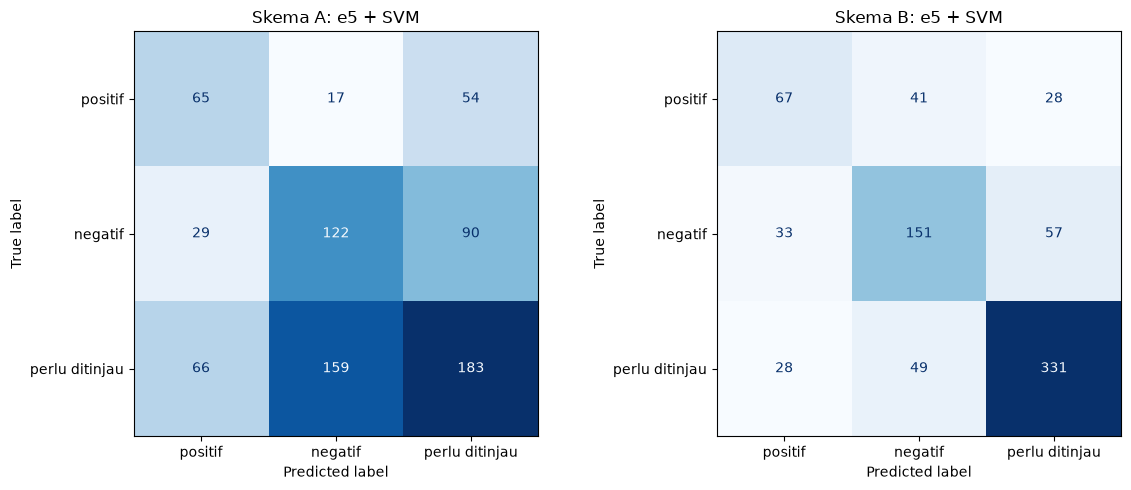

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for i, skema in enumerate(["A", "B"]):
    terbaik = max((k for k in akhir if k[0] == skema), key=lambda k: f1_score(y_test_3, akhir[k], average="macro"))
    print(f"===== Skema {skema}: {terbaik[1]} =====")
    print(classification_report(y_test_3, akhir[terbaik], digits=3))
    ConfusionMatrixDisplay.from_predictions(y_test_3, akhir[terbaik], labels=["positif", "negatif", TINJAU],
                                            cmap="Blues", ax=ax[i], colorbar=False)
    ax[i].set_title(f"Skema {skema}: {terbaik[1]}")
plt.tight_layout()
plt.show()

**Hasil:**

| Skema | Model | Pengaturan terbaik | Macro-F1 CV | Macro-F1 uji sebelum | Macro-F1 uji sesudah | Akurasi | Perlu ditinjau |
|---|---|---|---|---|---|---|---|
| **B** | **e5 + SVM** | `C` = 0,42 | 0,617 | 0,625 | **0,646** | **0,699** | 53,0% |
| B | e5 + Logistic Regression | `C` = 5,56 | 0,623 | 0,631 | 0,639 | 0,678 | 47,3% |
| A | e5 + SVM | `C` = 0,17, ambang 0,54 | 0,455 | 0,329 | 0,463 | 0,471 | 41,7% |
| A | e5 + Logistic Regression | `C` = 7,63, ambang 0,69 | 0,454 | 0,307 | 0,440 | 0,479 | 55,4% |
| A | TF-IDF + Logistic Regression | unigram, `min_df` = 2, `C` = 1,98, ambang 0,63 | 0,413 | 0,311 | 0,422 | 0,470 | 56,8% |

- Tuning **paling membantu skema A** (+0,11 sampai +0,13), terutama karena ambangnya diturunkan dari 0,7 menjadi 0,54-0,69. Meski begitu, skema A tetap jauh di bawah skema B.
- **Model akhir terbaik: skema B, e5 + SVM hasil tuning, macro-F1 0,646 dan akurasi 0,699.** Model ini menyerahkan 53% komentar ke "perlu ditinjau", hampir sama dengan proporsi sebenarnya di data uji (52%).

**Skor per label model terbaik setiap skema (data uji, 785 komentar):**

| Label | Skema A: precision | recall | F1 | Skema B: precision | recall | F1 |
|---|---|---|---|---|---|---|
| positif | 0,406 | 0,478 | 0,439 | 0,523 | 0,493 | 0,508 |
| negatif | 0,409 | 0,506 | 0,453 | 0,627 | 0,627 | 0,627 |
| perlu ditinjau | 0,560 | 0,449 | 0,498 | 0,796 | 0,811 | 0,803 |
| **macro** | **0,458** | **0,478** | **0,463** | **0,649** | **0,643** | **0,646** |

**Kesimpulan:**
- **Menyederhanakan label membantu, tetapi caranya menentukan.** Menggabungkan netral dan tidak relevan menjadi "perlu ditinjau" menaikkan skor model terbaik dari 0,582 (4 label) menjadi **0,646** (3 label). Kedua angka ini tidak sepenuhnya setara, karena tugas 3 label memang lebih mudah.
- **Melatih hanya dengan positif dan negatif (skema A) tidak berhasil.** Keraguan model bukan penanda yang baik untuk komentar yang perlu ditinjau. Model harus diberi contoh komentar seperti itu saat latihan (skema B).
- Label yang paling sulit sekarang adalah **positif** (F1 0,508). Jumlahnya paling sedikit, dan banyak komentar positif berupa sindiran atau argumen panjang yang mirip komentar negatif.

# **10. Rekomendasi Pengembangan**

Model akhir saat ini (skema B, e5 + SVM) mencapai **macro-F1 0,646, precision 0,649, dan recall 0,643** pada 3 label. Bab ini berisi langkah-langkah untuk menaikkannya ke kisaran **0,70-0,85**, diurutkan dari yang paling berpengaruh.

**Hal terpenting yang perlu dipahami dulu:** skor model tidak bisa jauh melampaui kualitas labelnya. Label saat ini dibuat oleh AI dengan kecocokan sekitar 0,60-0,68 terhadap label manual (Bab 5.4), dan model sudah mendekati batas itu. Jadi:

| Target | Yang dibutuhkan |
|---|---|
| **± 0,70** | cukup dengan perbaikan model dan cara klasifikasi (langkah 3-6) |
| **0,75-0,85** | **wajib** memperbaiki kualitas label (langkah 1-2), baru kemudian memperbaiki model |

## **10.1 Langkah 1: Perbaiki Kualitas Label (dampak terbesar)**

- **Labeli manual 300-500 komentar oleh 2 orang secara terpisah**, memakai panduan di Bab 5.1. Pilih komentar acak dari ketiga label, dan perbanyak komentar positif karena label ini paling lemah.
- **Ukur kesepakatan kedua orang** dengan Cohen's kappa (`sklearn.metrics.cohen_kappa_score`). Kalau kappa di bawah 0,6, panduannya masih kabur dan perlu dipertegas lagi sebelum melabeli lebih banyak.
- **Diskusikan komentar yang labelnya berbeda**, lalu tambahkan aturan baru ke panduan (seperti lima aturan di Bab 5.3).
- **Ganti label AI dengan label manual** untuk komentar yang sudah dilabeli ulang. Bisa juga melatih ulang pelabel AI dengan contoh-contoh baru ini, lalu melabeli ulang seluruh data.

Kalau dua manusia saja hanya sepakat sekitar 75%, angka itu adalah batas realistis untuk model. Target 0,85 hanya mungkin kalau kesepakatan manusia juga setinggi itu.

## **10.2 Langkah 2: Siapkan Data Uji yang Bersih**

- Data uji saat ini berlabel AI, dan bagian test gold set sudah dipakai untuk merumuskan aturan. Karena itu siapkan **100-200 komentar baru** yang belum pernah dipakai, lalu labeli manual (sebaiknya oleh 2 orang).
- Semua perbandingan berikutnya dinilai pada data uji bersih ini, supaya kenaikan skor bisa dipercaya.
- Laporkan juga skor **cross-validation (rata-rata ± simpangan baku)**, bukan hanya satu kali pembagian data, karena 785 komentar uji masih cukup kecil sehingga skornya bisa naik-turun beberapa persen.

## **10.3 Langkah 3: Klasifikasi Dua Tahap**

Pisahkan satu tugas sulit menjadi dua tugas yang lebih mudah:

| Tahap | Pertanyaan | Data latih |
|---|---|---|
| 1 | Apakah komentar ini **jelas sikapnya** atau **perlu ditinjau**? | semua komentar |
| 2 | Kalau jelas, **positif** atau **negatif**? | hanya positif dan negatif |

Tahap 1 sudah terbukti cukup mudah (F1 "perlu ditinjau" 0,80 di Bab 9), dan tahap 2 hanya membedakan dua label yang batasnya paling jelas. Implementasinya cukup dua model e5 + SVM yang dijalankan berurutan, memakai data di Bab 7.2 (`y_train_3` untuk tahap 1, `y_train_2` untuk tahap 2).

## **10.4 Langkah 4: Model dan Fitur yang Lebih Kuat**

- **Embedding yang lebih besar.** Ganti `intfloat/multilingual-e5-base` di 8.3 dengan `intfloat/multilingual-e5-large` atau `BAAI/bge-m3`. Keduanya multibahasa (Indonesia dan Inggris), dan cukup mengganti satu baris kode.
- **SetFit.** Metode *fine-tuning* untuk model *sentence-transformers* yang dirancang untuk data berlabel sedikit (ratusan sampai beberapa ribu komentar). Library: `setfit`.
- ***Fine-tuning* yang lebih serius di Google Colab** (GPU T4 atau lebih besar). Jangan bekukan lapisan embedding, latih 5-10 epoch, dan pakai sebagian data latih sebagai validasi untuk *early stopping*. Pada laptop dengan GPU 6 GB, XLM-RoBERTa terbukti tidak stabil (Bab 8.2).
- **Gabungkan fitur.** Tempelkan vektor TF-IDF (dengan bigram) di samping vektor e5, karena TF-IDF menangkap kata kunci seperti "not replace", sedangkan e5 menangkap makna kalimat.

## **10.5 Langkah 5: Atasi Label Positif yang Lemah**

Positif adalah label dengan F1 terendah (0,508) dan jumlah paling sedikit (17%).

- **Tambah data positif.** Ambil komentar dari video yang lebih banyak membahas sisi optimis AI, lalu labeli.
- **Geser ambang per label.** Setelah model skema B memberi peluang untuk tiap label, naikkan sedikit bobot label positif dan cari nilai terbaiknya dengan cross-validation di data latih (bukan di data uji), seperti pencarian ambang di Bab 9.
- **Periksa contoh yang salah tebak.** Tampilkan komentar positif yang tertebak negatif. Kalau ternyata labelnya yang keliru, kembali ke langkah 1.

## **10.6 Langkah 6: Gabungkan Beberapa Model (Ensemble)**

Gabungkan tebakan beberapa model terbaik, misalnya e5 + SVM, e5 + Logistic Regression, dan TF-IDF + Logistic Regression, dengan `sklearn.ensemble.VotingClassifier` (voting berdasarkan peluang). Model yang berbeda sering salah pada komentar yang berbeda, sehingga gabungannya biasanya sedikit lebih stabil.

## **10.7 Urutan Pengerjaan yang Disarankan**

1. Langkah 2 dulu (data uji bersih), supaya setiap perubahan bisa diukur dengan jujur.
2. Langkah 3 dan 4 (dua tahap + embedding lebih besar): paling cepat dicoba, kemungkinan cukup untuk mencapai sekitar 0,70.
3. Langkah 1 dan 5 (kualitas label dan label positif): paling banyak tenaga, tetapi satu-satunya jalan menuju 0,80-0,85.
4. Langkah 6 terakhir, sebagai penyempurnaan.

Semua perkiraan di atas adalah **dugaan** berdasarkan hasil notebook ini, dan harus dibuktikan dengan percobaan.